# Spotify Bivariate Analysis — Member 2

This standalone notebook contains Member 2's bivariate analysis for the Spotify EDA project. It was extracted from Section 8 of the team notebook so it can be reviewed and run separately. The main `Spotify_EDA.ipynb` is left unchanged.

## 1. Purpose and scope

Bivariate analysis studies the relationship between **two** variables. This notebook covers:

- **A.** Numerical relationships: 10 scatter plots with Pearson and Spearman correlations.
- **B.** Pearson and Spearman correlation heatmaps.
- **C.** Popularity by language.
- **D.** Popularity by key, mode, and time signature.
- **E.** Top 10 and bottom 10 tracks by popularity.

Every relationship uses **pairwise valid observations**. Scatter plots draw a reproducible sample of at most 5,000 points for readability, but correlations use **all** valid rows.

This notebook loads the existing cleaned dataset produced by Section 6 of the main notebook. It does not re-clean the raw file and does not modify the cleaned data in place.

Correlation describes association only. **Correlation does not prove causation.**

## 2. Libraries and chart style

These are the same libraries and shared Spotify chart theme used by the main notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.spotify_chart_style import (
    apply_spotify_style, spotify_green, muted_grey, muted_blue, muted_sand,
)

apply_spotify_style()


## 3. Load the existing cleaned data

The main notebook already removed exact duplicate rows and marked invalid sentinel values as missing. We load that existing cleaned CSV as `df_clean` and do not repeat the cleaning pipeline.

In [2]:
from pathlib import Path

cleaned_path = Path('data/processed/cleaned_spotify_tracks.csv')
df_clean = pd.read_csv(cleaned_path)

print('Rows and columns:', df_clean.shape)
print('Missing cells:', int(df_clean.isna().sum().sum()))
print('Duplicate rows:', int(df_clean.duplicated().sum()))
print('Duplicate track IDs:', int(df_clean['track_id'].duplicated().sum()))
print('Loaded cleaned data from:', cleaned_path)


Rows and columns: (62239, 22)
Missing cells: 420
Duplicate rows: 0
Duplicate track IDs: 0
Loaded cleaned data from: data\processed\cleaned_spotify_tracks.csv


## 4. Prepare the bivariate inputs

We create the output folders and make one analysis copy that contains only the numeric columns we need. Duration is divided by 60,000 to convert milliseconds to minutes **in the copy**; `df_clean` itself is left unchanged.

In [3]:
from pathlib import Path
import textwrap

from src.spotify_chart_style import (
    spotify_diverging, elevated_dark, spotify_black, text_white,
)

bivariate_dir = Path('outputs/graphs/bivariate')
table_dir = Path('outputs/tables')
report_dir = Path('outputs/reports')
for folder in (bivariate_dir, table_dir, report_dir):
    folder.mkdir(parents=True, exist_ok=True)

numeric_features = [
    'popularity', 'energy', 'danceability', 'valence', 'acousticness',
    'loudness', 'instrumentalness', 'liveness', 'speechiness', 'tempo',
]

# Work on a copy so the cleaned DataFrame is never modified.
analysis_data = df_clean[numeric_features + ['duration_ms']].copy()
analysis_data['duration_min'] = analysis_data['duration_ms'] / 60000.0
analysis_data = analysis_data.drop(columns='duration_ms')

correlation_features = [
    'popularity', 'energy', 'danceability', 'valence', 'acousticness',
    'loudness', 'instrumentalness', 'liveness', 'speechiness',
    'tempo', 'duration_min',
]

correlation_labels = {
    'popularity': 'Popularity',
    'energy': 'Energy',
    'danceability': 'Danceability',
    'valence': 'Valence',
    'acousticness': 'Acousticness',
    'loudness': 'Loudness',
    'instrumentalness': 'Instrumentalness',
    'liveness': 'Liveness',
    'speechiness': 'Speechiness',
    'tempo': 'Tempo',
    'duration_min': 'Duration (min)',
}

print('Tracks available for bivariate analysis:', f'{len(analysis_data):,}')
print('Maximum points used in one scatter plot:', f'{min(5000, len(analysis_data)):,}')
print('Duration is plotted in minutes; correlations use the same converted values.')


Tracks available for bivariate analysis: 62,239
Maximum points used in one scatter plot: 5,000
Duration is plotted in minutes; correlations use the same converted values.


## 5. A. Numerical relationship analysis

Each scatter plot below compares one audio feature with popularity. The code also calculates Pearson and Spearman correlations from **all pairwise valid observations**.

- **Pearson** measures the strength of a straight-line relationship.
- **Spearman** measures the strength of a monotonic relationship (whether one variable generally rises or falls with the other, without requiring a straight line).
- A reproducible sample (`random_state=42`) of at most 5,000 points is drawn only for the picture.

The duration plot limits its x-axis to the 99th percentile (about 8.67 minutes) so the bulk of the data is readable. Longer tracks remain in the correlation calculation.

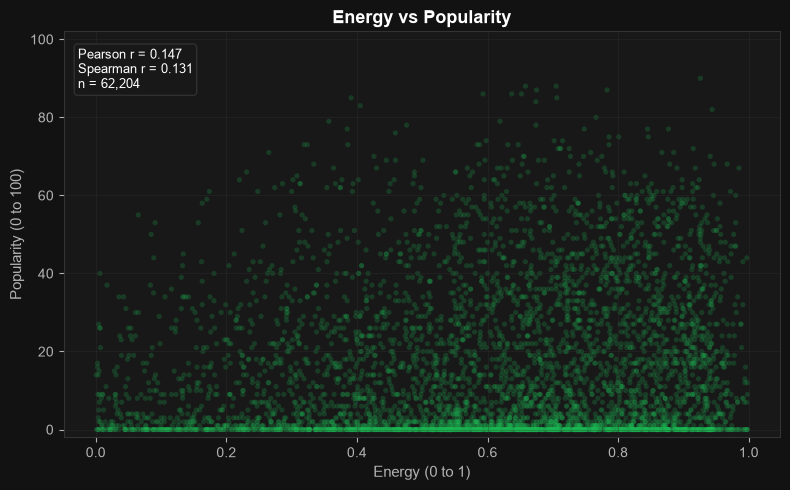

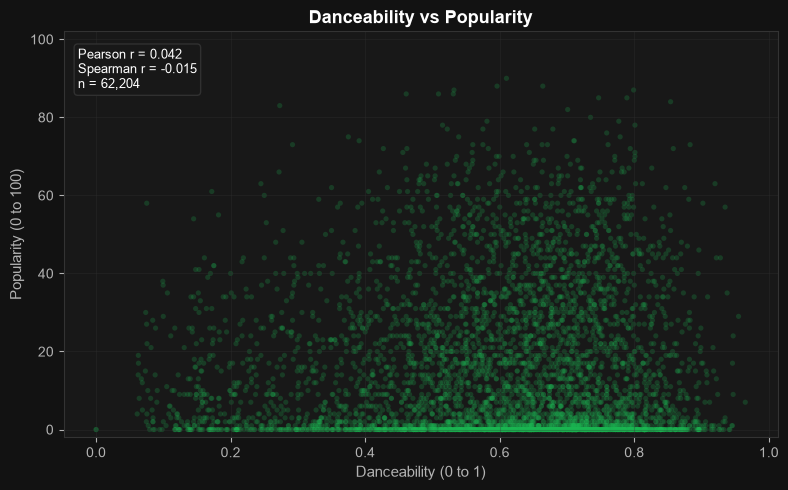

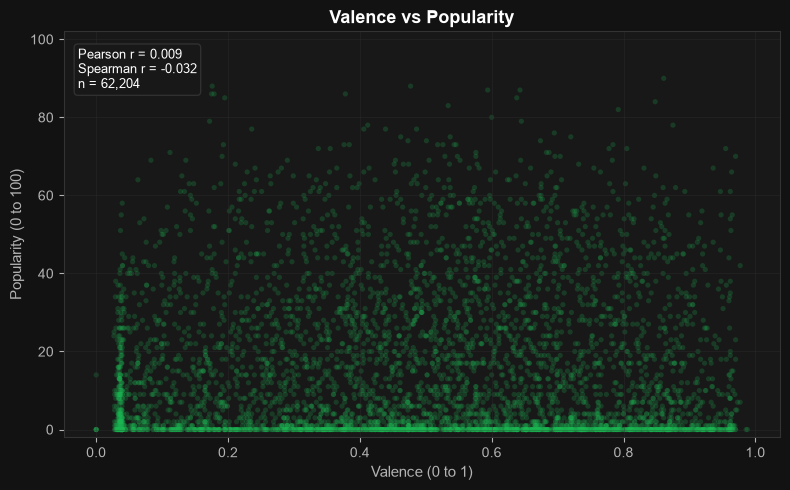

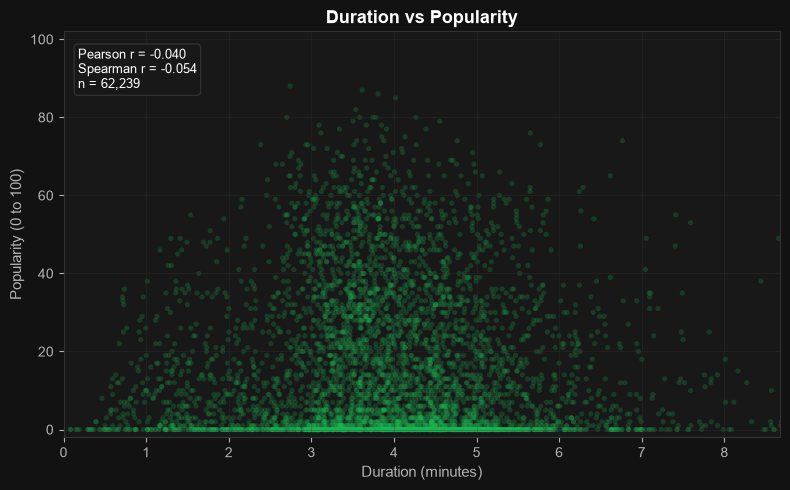

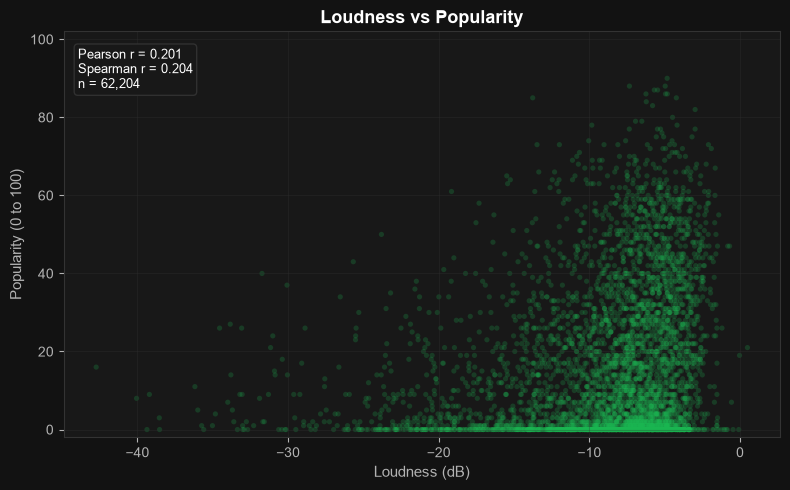

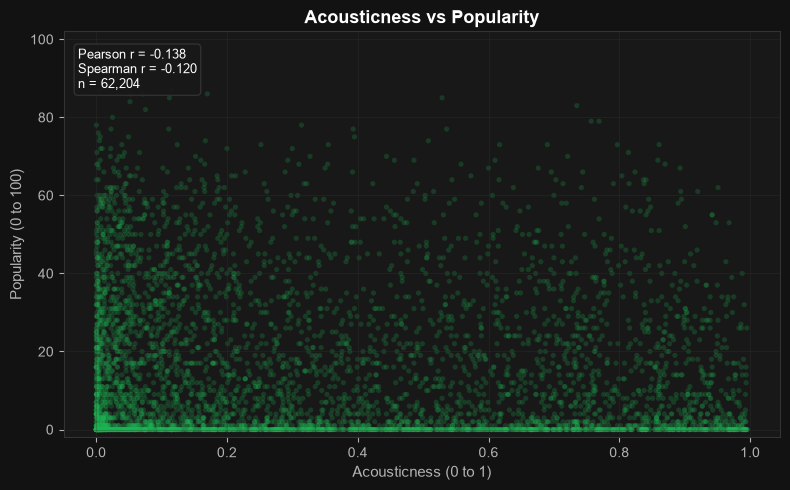

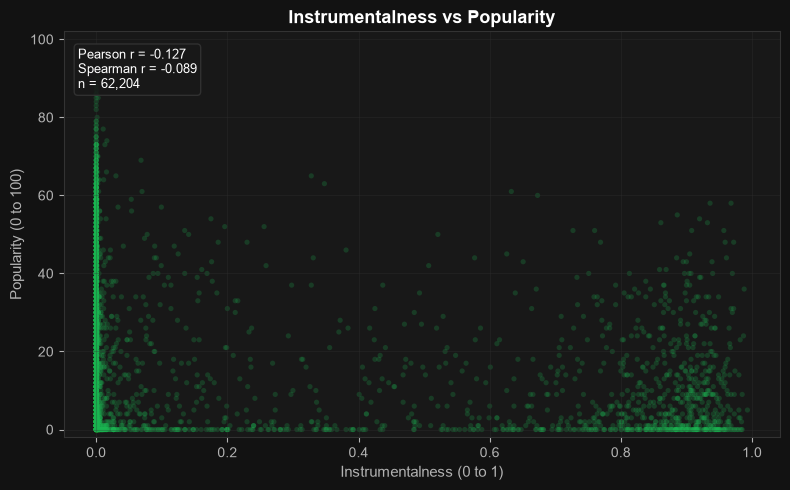

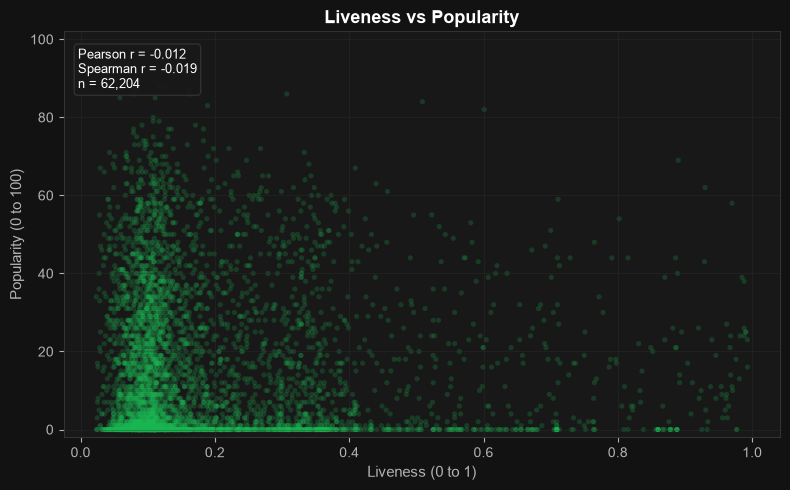

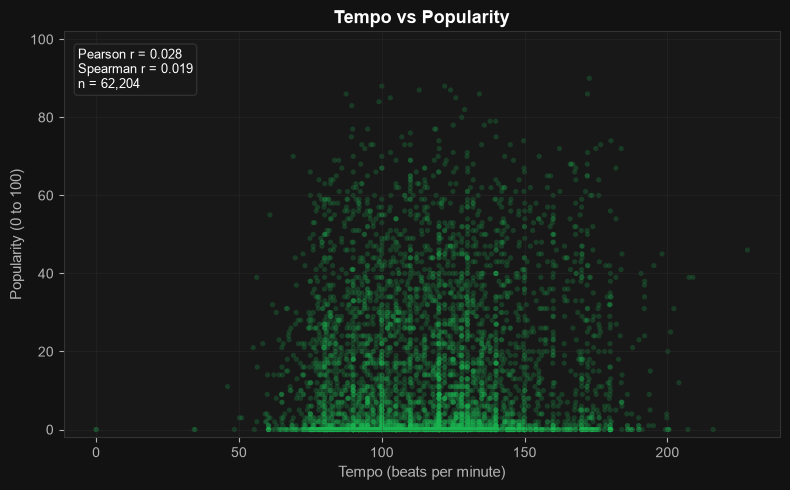

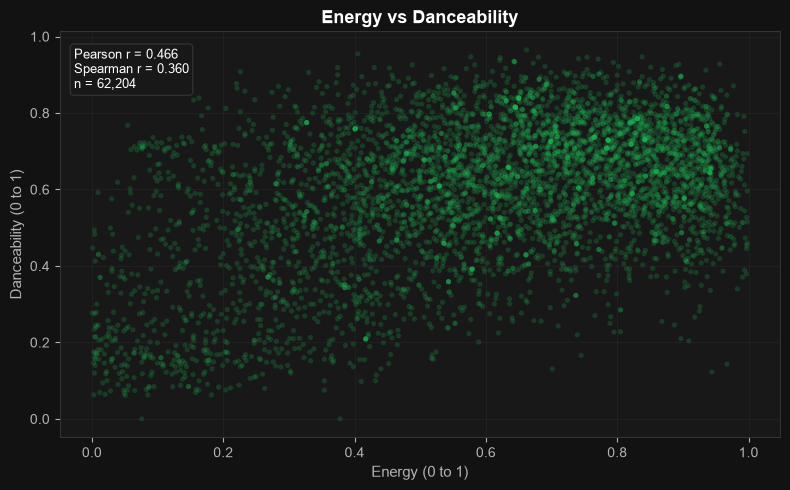

Correlations for the 10 plotted relationships (all valid rows):
      Variable X   Variable Y  Pearson r  Spearman r  Valid n
          Energy   Popularity      0.147       0.131    62204
    Danceability   Popularity      0.042      -0.015    62204
         Valence   Popularity      0.009      -0.032    62204
  Duration (min)   Popularity     -0.040      -0.054    62239
        Loudness   Popularity      0.201       0.204    62204
    Acousticness   Popularity     -0.138      -0.120    62204
Instrumentalness   Popularity     -0.127      -0.089    62204
        Liveness   Popularity     -0.012      -0.019    62204
           Tempo   Popularity      0.028       0.019    62204
          Energy Danceability      0.466       0.360    62204


In [4]:
# A reproducible sample is used only for drawing the points.
# Correlations are calculated from all pairwise valid rows.
scatter_pairs = [
    ('energy', 'popularity', 'Energy vs Popularity',
     'Energy (0 to 1)', 'Popularity (0 to 100)', 'energy_vs_popularity.png'),
    ('danceability', 'popularity', 'Danceability vs Popularity',
     'Danceability (0 to 1)', 'Popularity (0 to 100)', 'danceability_vs_popularity.png'),
    ('valence', 'popularity', 'Valence vs Popularity',
     'Valence (0 to 1)', 'Popularity (0 to 100)', 'valence_vs_popularity.png'),
    ('duration_min', 'popularity', 'Duration vs Popularity',
     'Duration (minutes)', 'Popularity (0 to 100)', 'duration_vs_popularity.png'),
    ('loudness', 'popularity', 'Loudness vs Popularity',
     'Loudness (dB)', 'Popularity (0 to 100)', 'loudness_vs_popularity.png'),
    ('acousticness', 'popularity', 'Acousticness vs Popularity',
     'Acousticness (0 to 1)', 'Popularity (0 to 100)', 'acousticness_vs_popularity.png'),
    ('instrumentalness', 'popularity', 'Instrumentalness vs Popularity',
     'Instrumentalness (0 to 1)', 'Popularity (0 to 100)', 'instrumentalness_vs_popularity.png'),
    ('liveness', 'popularity', 'Liveness vs Popularity',
     'Liveness (0 to 1)', 'Popularity (0 to 100)', 'liveness_vs_popularity.png'),
    ('tempo', 'popularity', 'Tempo vs Popularity',
     'Tempo (beats per minute)', 'Popularity (0 to 100)', 'tempo_vs_popularity.png'),
    ('energy', 'danceability', 'Energy vs Danceability',
     'Energy (0 to 1)', 'Danceability (0 to 1)', 'energy_vs_danceability.png'),
]

scatter_results = []

for x_column, y_column, title, x_label, y_label, filename in scatter_pairs:
    pair_data = analysis_data[[x_column, y_column]].dropna()
    pearson_r = pair_data[x_column].corr(pair_data[y_column], method='pearson')
    spearman_r = pair_data[x_column].corr(pair_data[y_column], method='spearman')

    scatter_results.append({
        'Variable X': correlation_labels[x_column],
        'Variable Y': correlation_labels[y_column],
        'Pearson r': round(pearson_r, 3),
        'Spearman r': round(spearman_r, 3),
        'Valid n': len(pair_data),
    })

    visual_data = pair_data.sample(n=min(5000, len(pair_data)), random_state=42)

    plt.figure(figsize=(8, 5))
    plt.scatter(
        visual_data[x_column], visual_data[y_column],
        color=spotify_green, alpha=0.22, s=14, edgecolors='none',
    )
    if x_column == 'duration_min':
        plt.xlim(0, pair_data[x_column].quantile(0.99))
    if y_column == 'popularity':
        plt.ylim(-2, 102)

    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.grid(True, alpha=0.3)
    plt.text(
        0.02, 0.96,
        f'Pearson r = {pearson_r:.3f}\nSpearman r = {spearman_r:.3f}\nn = {len(pair_data):,}',
        transform=plt.gca().transAxes, va='top', ha='left', fontsize=9,
        color=text_white,
        bbox=dict(boxstyle='round', facecolor=elevated_dark, edgecolor='#333333', alpha=0.9),
    )
    plt.tight_layout()
    plt.savefig(bivariate_dir / filename, dpi=180, facecolor=plt.rcParams['figure.facecolor'])
    plt.show(block=False)
    plt.close()

scatter_results = pd.DataFrame(scatter_results)
print('Correlations for the 10 plotted relationships (all valid rows):')
print(scatter_results.to_string(index=False))


#### Energy vs Popularity

1. **What it shows:** Each point is a track; the horizontal axis is energy (0-1) and the vertical axis is popularity (0-100).
2. **Numerical evidence:** Pearson r = **0.147**, Spearman r = **0.131**, n = **62,204**.
3. **Pattern:** There is a very slight upward tendency, but the cloud of points is wide and many tracks sit at popularity 0 across the whole energy range.
4. **Meaning:** Higher-energy tracks are *slightly* more likely to have higher popularity in this dataset, but the relationship is weak. Energy explains only about 2% of the variation in popularity (r² ≈ 0.022), so it is not a useful stand-alone predictor.
5. **Limit:** Popularity is heavily zero-inflated (17,698 tracks have popularity 0), the plot shows a 5,000-point sample, and this is an observational association, not evidence that energy causes popularity.

#### Danceability vs Popularity

1. **What it shows:** Danceability (0-1) against popularity (0-100).
2. **Numerical evidence:** Pearson r = **0.042**, Spearman r = **-0.015**, n = **62,204**.
3. **Pattern:** The points form an almost flat cloud. Pearson is slightly positive while Spearman is slightly negative, which suggests no consistent monotonic trend.
4. **Meaning:** Danceability alone has a negligible relationship with popularity in this dataset.
5. **Limit:** The sign change between methods and the large number of popularity-zero tracks make any tiny coefficient unreliable as a practical finding; association is not causation.

#### Valence vs Popularity

1. **What it shows:** Valence (0-1), Spotify's estimate of positive mood, against popularity (0-100).
2. **Numerical evidence:** Pearson r = **0.009**, Spearman r = **-0.032**, n = **62,204**.
3. **Pattern:** The points are spread across the full valence range at every popularity level.
4. **Meaning:** Valence has essentially no linear or monotonic relationship with popularity here.
5. **Limit:** Valence is an audio estimate, not a direct measure of listener enjoyment; the zero-inflated popularity score and observational design limit conclusions.

#### Duration vs Popularity

1. **What it shows:** Track duration in minutes against popularity. The x-axis is limited to the 99th percentile (8.67 minutes) for readability.
2. **Numerical evidence:** Pearson r = **-0.040**, Spearman r = **-0.054**, n = **62,239**.
3. **Pattern:** Most tracks last about 4 minutes (median 3.94), and popularity is spread across short and long tracks. A small number of tracks longer than 12 minutes are outside the plotted range but are included in the correlation.
4. **Meaning:** Longer tracks are very slightly less popular on average, but the effect is negligible.
5. **Limit:** The full duration range reaches 76.4 minutes, so the displayed x-range hides rare extremes; correlation does not prove that length causes popularity.

#### Loudness vs Popularity

1. **What it shows:** Loudness in decibels (dB) against popularity.
2. **Numerical evidence:** Pearson r = **0.201**, Spearman r = **0.204**, n = **62,204**.
3. **Pattern:** There is a gentle upward drift: louder tracks (closer to 0 dB) tend to have somewhat higher popularity, though the points remain widely scattered.
4. **Meaning:** Loudness has the **strongest positive popularity association** among the features examined, but it is still weak. It explains only about 4% of popularity variation (r² ≈ 0.040).
5. **Limit:** Loudness is strongly correlated with energy (Pearson r = 0.801), so their associations with popularity partly overlap; neither should be read as a causal lever.

#### Acousticness vs Popularity

1. **What it shows:** Acousticness (0-1) against popularity.
2. **Numerical evidence:** Pearson r = **-0.138**, Spearman r = **-0.120**, n = **62,204**.
3. **Pattern:** There is a mild downward tendency: more acoustic tracks tend to be somewhat less popular, but there is large overlap.
4. **Meaning:** The association is weak and negative. Acousticness is not a strong explanation of popularity.
5. **Limit:** Acousticness is strongly negatively correlated with energy (Pearson r = -0.643), so the pattern may reflect the broader energy/loudness profile rather than acousticness itself.

#### Instrumentalness vs Popularity

1. **What it shows:** Instrumentalness (0-1) against popularity.
2. **Numerical evidence:** Pearson r = **-0.127**, Spearman r = **-0.089**, n = **62,204**.
3. **Pattern:** The points are concentrated near zero instrumentalness, with a weak downward tendency as instrumentalness rises.
4. **Meaning:** More instrumental tracks are slightly less popular in this dataset, but the relationship is weak.
5. **Limit:** The feature is highly skewed (many tracks have very low values), and language or catalogue composition could also differ across instrumental tracks; association is not causation.

#### Liveness vs Popularity

1. **What it shows:** Liveness (0-1) against popularity.
2. **Numerical evidence:** Pearson r = **-0.012**, Spearman r = **-0.019**, n = **62,204**.
3. **Pattern:** No visible trend; tracks at every liveness level appear across the popularity range.
4. **Meaning:** Liveness has a negligible relationship with popularity here.
5. **Limit:** A near-zero correlation only rules out a strong *linear/monotonic* pattern; it does not prove that liveness is irrelevant in every possible context.

#### Tempo vs Popularity

1. **What it shows:** Tempo in beats per minute against popularity.
2. **Numerical evidence:** Pearson r = **0.028**, Spearman r = **0.019**, n = **62,204**.
3. **Pattern:** The point cloud is essentially flat across the tempo range.
4. **Meaning:** Tempo has a negligible relationship with popularity in this dataset.
5. **Limit:** The result is observational and dominated by the many low-popularity tracks; it does not show how tempo affects an individual listener.

#### Energy vs Danceability

1. **What it shows:** Two audio features plotted against each other, without popularity on either axis.
2. **Numerical evidence:** Pearson r = **0.466**, Spearman r = **0.360**, n = **62,204**.
3. **Pattern:** Higher-energy tracks tend to be more danceable, but the spread is wide; the relationship is moderate, not one-to-one.
4. **Meaning:** Energy and danceability share a moderate positive association, so they carry some overlapping information.
5. **Limit:** Both are Spotify audio estimates, and a correlation between them says nothing about which one influences the other, if either.

## 6. B. Correlation analysis

The two heatmaps use the same 11 numeric columns. **Key, mode, and time_signature are deliberately excluded from the numerical heatmaps** because their numeric codes are labels, not measurements. They are analysed as categories in Section D.

The correlation results table uses **pairwise valid observations** for every pair. This means each coefficient has its own valid `n`.

In [5]:
# Pearson: straight-line association. Spearman: monotonic association.
pearson_corr = analysis_data[correlation_features].corr(method='pearson')
spearman_corr = analysis_data[correlation_features].corr(method='spearman')

pearson_display = pearson_corr.rename(index=correlation_labels, columns=correlation_labels)
spearman_display = spearman_corr.rename(index=correlation_labels, columns=correlation_labels)

# Build one row per unique pair, using pairwise complete observations.
correlation_rows = []
for position, x_column in enumerate(correlation_features):
    for y_column in correlation_features[position + 1:]:
        pair_data = analysis_data[[x_column, y_column]].dropna()
        correlation_rows.append({
            'Variable X': correlation_labels[x_column],
            'Variable Y': correlation_labels[y_column],
            'Pearson r': pair_data[x_column].corr(pair_data[y_column], method='pearson'),
            'Spearman r': pair_data[x_column].corr(pair_data[y_column], method='spearman'),
            'Valid n': len(pair_data),
        })

correlation_results = pd.DataFrame(correlation_rows)
correlation_results.round(6).to_csv(
    table_dir / 'MEMBER2_CORRELATION_RESULTS.csv', index=False
)

popularity_results = correlation_results[
    (correlation_results['Variable X'] == 'Popularity')
    | (correlation_results['Variable Y'] == 'Popularity')
].copy()
popularity_results['Absolute Pearson |r|'] = popularity_results['Pearson r'].abs()
popularity_results = (
    popularity_results.sort_values('Absolute Pearson |r|', ascending=False)
    .drop(columns='Absolute Pearson |r|')
)

print('Popularity relationships ranked by absolute Pearson correlation:')
print(popularity_results.round(3).to_string(index=False))
print()
print(f'Full table saved with {len(correlation_results)} unique pairs:')
print('outputs/tables/MEMBER2_CORRELATION_RESULTS.csv')


Popularity relationships ranked by absolute Pearson correlation:
Variable X       Variable Y  Pearson r  Spearman r  Valid n
Popularity         Loudness      0.201       0.204    62204
Popularity           Energy      0.147       0.131    62204
Popularity     Acousticness     -0.138      -0.120    62204
Popularity Instrumentalness     -0.127      -0.089    62204
Popularity      Speechiness     -0.054      -0.017    62204
Popularity     Danceability      0.042      -0.015    62204
Popularity   Duration (min)     -0.040      -0.054    62239
Popularity            Tempo      0.028       0.019    62204
Popularity         Liveness     -0.012      -0.019    62204
Popularity          Valence      0.009      -0.032    62204

Full table saved with 55 unique pairs:
outputs/tables/MEMBER2_CORRELATION_RESULTS.csv


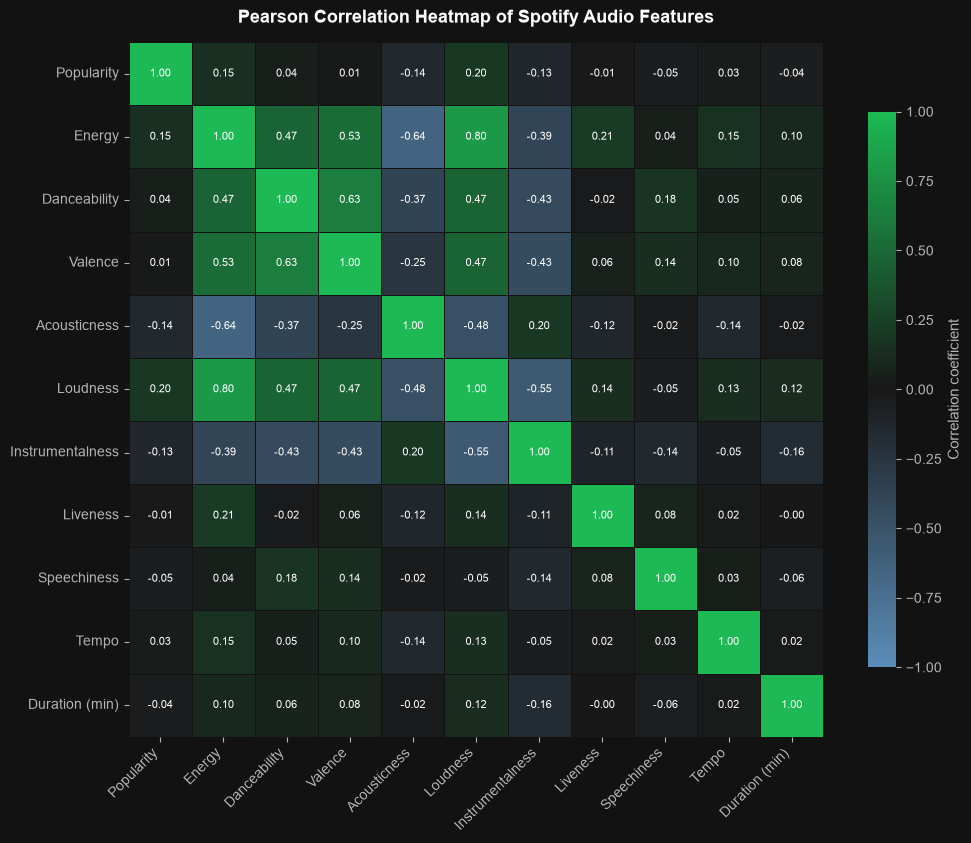

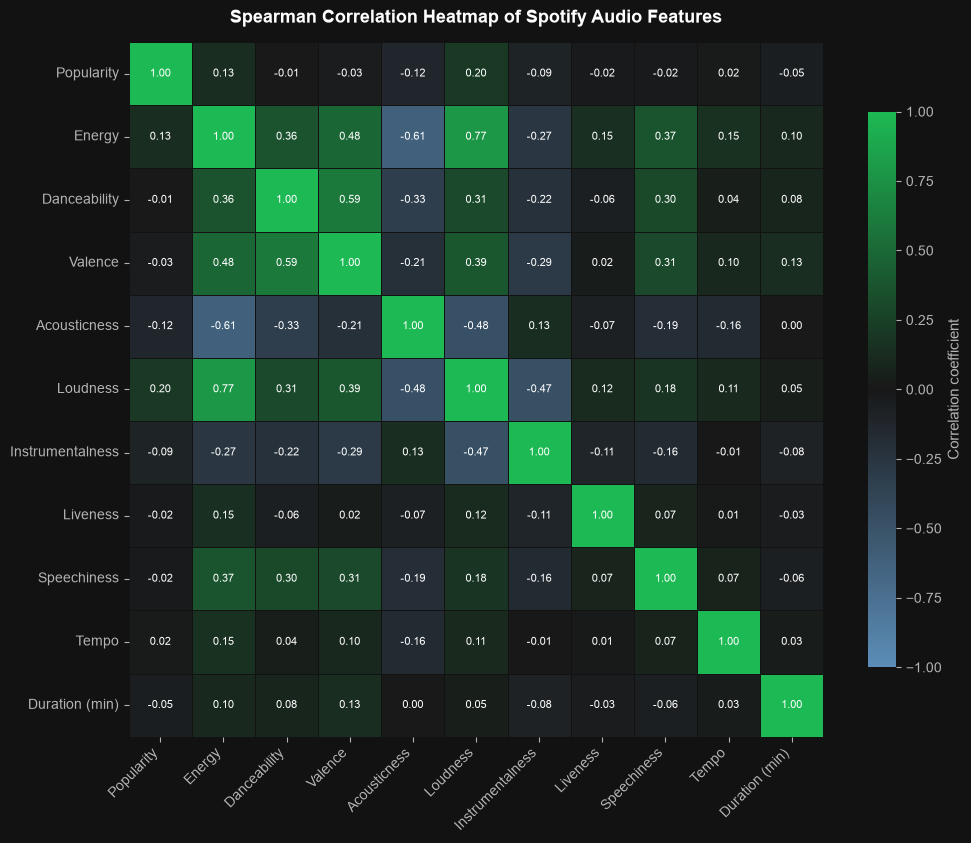

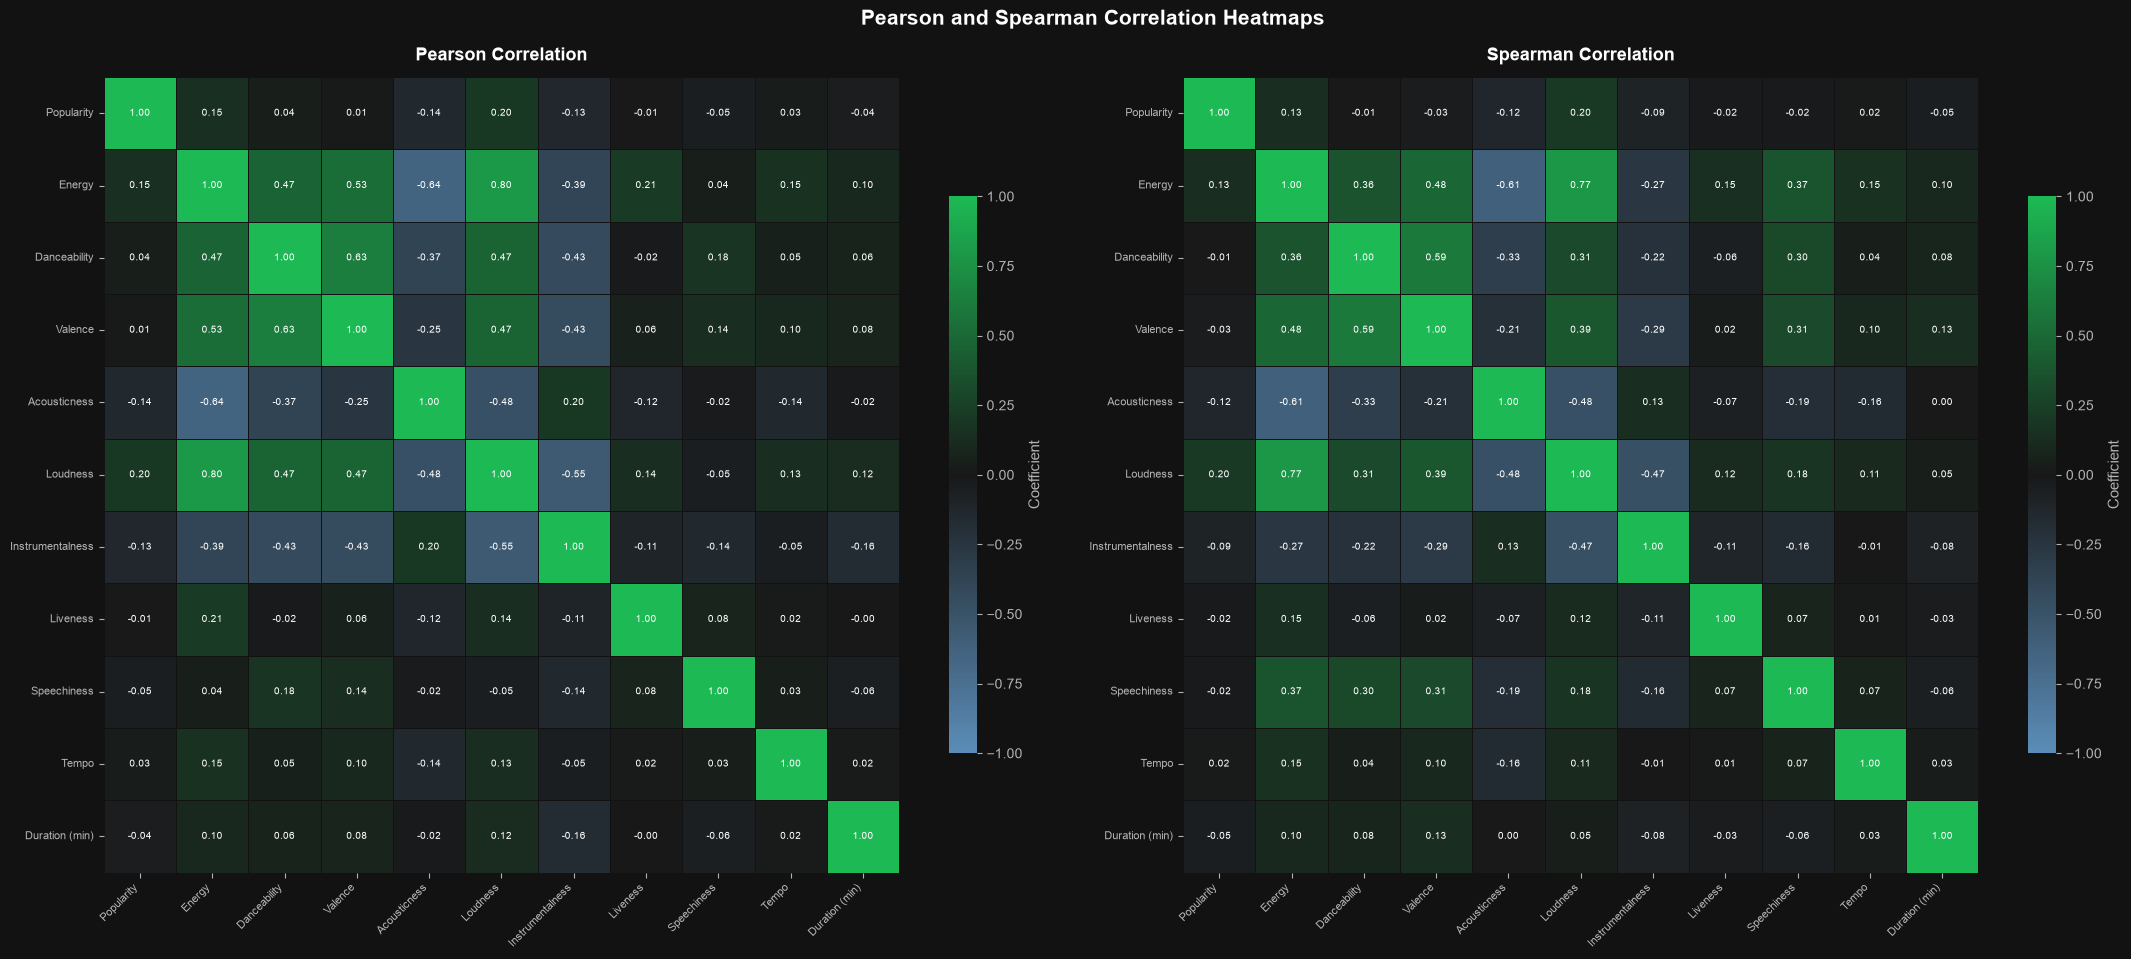

In [6]:
def draw_correlation_heatmap(matrix, title, filename):
    plt.figure(figsize=(10.5, 8.5))
    sns.heatmap(
        matrix,
        annot=True,
        fmt='.2f',
        cmap=spotify_diverging,
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.6,
        linecolor=spotify_black,
        annot_kws={'fontsize': 8, 'color': text_white},
        cbar_kws={'label': 'Correlation coefficient', 'shrink': 0.8},
    )
    plt.title(title, pad=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        bivariate_dir / filename, dpi=180,
        facecolor=plt.rcParams['figure.facecolor'], bbox_inches='tight',
    )
    plt.show(block=False)
    plt.close()


draw_correlation_heatmap(
    pearson_display,
    'Pearson Correlation Heatmap of Spotify Audio Features',
    'correlation_heatmap_pearson.png',
)
draw_correlation_heatmap(
    spearman_display,
    'Spearman Correlation Heatmap of Spotify Audio Features',
    'correlation_heatmap_spearman.png',
)

# A single side-by-side image is also saved with the required short filename.
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for axis, matrix, title in [
    (axes[0], pearson_display, 'Pearson Correlation'),
    (axes[1], spearman_display, 'Spearman Correlation'),
]:
    sns.heatmap(
        matrix,
        annot=True,
        fmt='.2f',
        cmap=spotify_diverging,
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        linecolor=spotify_black,
        annot_kws={'fontsize': 7, 'color': text_white},
        cbar_kws={'label': 'Coefficient', 'shrink': 0.7},
        ax=axis,
    )
    axis.set_title(title, pad=12)
    axis.set_xticklabels(matrix.columns, rotation=45, ha='right', fontsize=8)
    axis.set_yticklabels(matrix.index, rotation=0, fontsize=8)

plt.suptitle('Pearson and Spearman Correlation Heatmaps', y=1.02, color=text_white, fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(
    bivariate_dir / 'correlation_heatmap.png', dpi=180,
    facecolor=plt.rcParams['figure.facecolor'], bbox_inches='tight',
)
plt.show(block=False)
plt.close()


#### Correlation heatmap interpretation

1. **What the graphs show:** The Pearson heatmap measures straight-line association, and the Spearman heatmap measures monotonic association. Both use the same 11 numeric columns. Key, mode, and time_signature are excluded because their numeric codes are category labels, not measurements.
2. **Numerical evidence:** The strongest feature-to-feature values are energy vs loudness (**0.801** Pearson, **0.774** Spearman), energy vs acousticness (**-0.643**, **-0.612**), danceability vs valence (**0.632**, **0.595**), and energy vs danceability (**0.466**, **0.360**). The largest popularity values are loudness (**0.201**, **0.204**), energy (**0.147**, **0.131**), acousticness (**-0.138**, **-0.120**), and instrumentalness (**-0.127**, **-0.089**).
3. **Pattern:** Audio features are often moderately or strongly related to each other. Popularity, by contrast, has only weak associations. Positive relationships mean the variables tend to increase together; negative relationships mean one tends to decrease as the other increases. Valence (0.009 / -0.032), liveness (-0.012 / -0.019), tempo (0.028 / 0.019), and duration (-0.040 / -0.054) are negligible.
4. **What it means:** No single audio feature is a strong stand-alone explanation of popularity. The feature-to-feature overlaps also mean a simple popularity correlation may partly reflect another feature. Pearson and Spearman disagree slightly in sign for danceability (0.042 vs -0.015) and valence (0.009 vs -0.032), so there is no consistent monotonic pattern for those two.
5. **Limitations:** These are pairwise correlations, not multivariable effects. They do not control for language, year, artist fame, playlist exposure, or region. Popularity is heavily zero-inflated (17,698 tracks at 0), and correlation does not prove causation.

## 7. C. Popularity by language

This grouped boxplot compares the popularity distribution across the language categories that actually exist in the cleaned data. The sample size is shown below each language name. Outlier points are hidden to keep the boxes readable; they remain in the data and in the summary table.

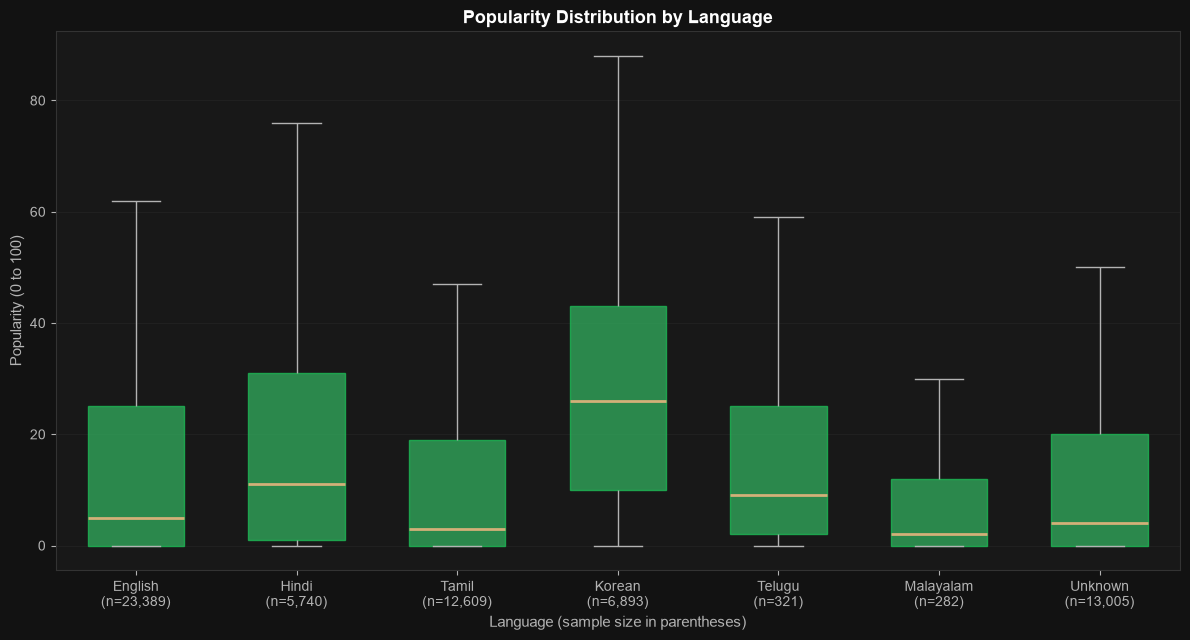

In [7]:
language_order = [
    'English', 'Hindi', 'Tamil', 'Korean', 'Telugu', 'Malayalam', 'Unknown',
]
language_order = [name for name in language_order
                  if name in df_clean['language'].unique()]
language_counts = df_clean['language'].value_counts()
language_data = df_clean[df_clean['language'].isin(language_order)].copy()

plt.figure(figsize=(12, 6.5))
sns.boxplot(
    data=language_data,
    x='language',
    y='popularity',
    order=language_order,
    color=spotify_green,
    width=0.6,
    showfliers=False,
    medianprops=dict(color=muted_sand, linewidth=2),
    boxprops=dict(alpha=0.8, edgecolor=spotify_green),
    whiskerprops=dict(color=muted_grey),
    capprops=dict(color=muted_grey),
)
plt.xticks(
    range(len(language_order)),
    [f'{name}\n(n={language_counts[name]:,})' for name in language_order],
)
plt.title('Popularity Distribution by Language')
plt.xlabel('Language (sample size in parentheses)')
plt.ylabel('Popularity (0 to 100)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    bivariate_dir / 'popularity_by_language.png', dpi=180,
    facecolor=plt.rcParams['figure.facecolor'],
)
plt.show(block=False)
plt.close()


#### Language interpretation

1. **What the graph shows:** A grouped boxplot of popularity for the seven language categories present in the cleaned data. Each x-axis label includes its sample size.
2. **Numerical evidence:** English n = 23,389 (mean 14.76, median 5); Hindi n = 5,740 (18.20, 11); Tamil n = 12,609 (11.91, 3); Korean n = 6,893 (27.55, 26); Telugu n = 321 (14.32, 9); Malayalam n = 282 (7.32, 2); Unknown n = 13,005 (12.26, 4).
3. **Pattern:** Korean has the highest centre (median 26). Malayalam (median 2), Tamil (median 3), and Unknown (median 4) have lower centres. The boxes overlap, but the Korean distribution is clearly shifted upward in this dataset.
4. **What it means:** Popularity differs descriptively across language groups. This may reflect catalogue composition, artists, release years, regional listener coverage, and how the data was collected; it does **not** show that language causes higher or lower popularity.
5. **Limitations:** Group sizes are very uneven, popularity is zero-inflated, outliers are hidden for readability, and no significance test or control for other factors is claimed.

## 8. D. Popularity by musical categories

Key, mode, and time signature are **categories**, not continuous measurements. We therefore treat their numeric codes as labels and use boxplots plus counts instead of scatter plots. Sentinels already converted to missing values are excluded from these summaries.

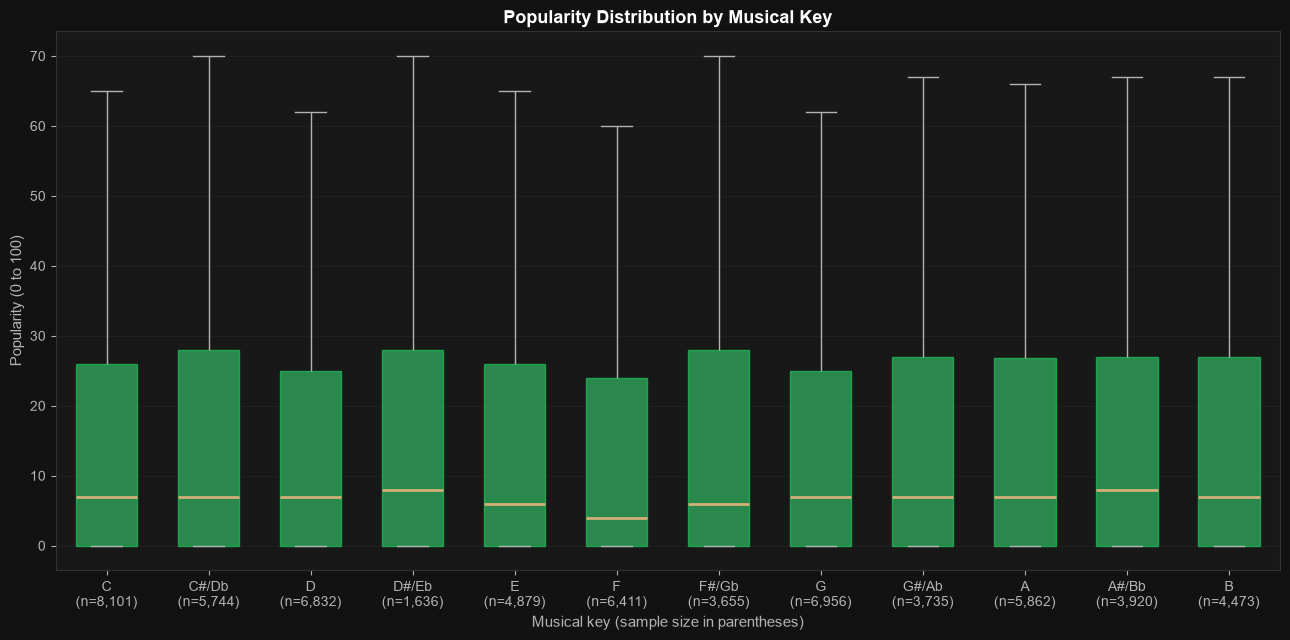

In [8]:
key_names = {
    0: 'C', 1: 'C#/Db', 2: 'D', 3: 'D#/Eb', 4: 'E', 5: 'F',
    6: 'F#/Gb', 7: 'G', 8: 'G#/Ab', 9: 'A', 10: 'A#/Bb', 11: 'B',
}
key_order = list(range(12))
key_data = df_clean.dropna(subset=['key']).copy()
key_data['key_label'] = key_data['key'].map(key_names)
key_order_labels = [key_names[key] for key in key_order]
key_counts = key_data['key_label'].value_counts()

plt.figure(figsize=(13, 6.5))
sns.boxplot(
    data=key_data,
    x='key_label',
    y='popularity',
    order=key_order_labels,
    color=spotify_green,
    width=0.6,
    showfliers=False,
    medianprops=dict(color=muted_sand, linewidth=2),
    boxprops=dict(alpha=0.8, edgecolor=spotify_green),
    whiskerprops=dict(color=muted_grey),
    capprops=dict(color=muted_grey),
)
plt.xticks(
    range(len(key_order)),
    [f'{key_names[key]}\n(n={key_counts[key_names[key]]:,})' for key in key_order],
)
plt.title('Popularity Distribution by Musical Key')
plt.xlabel('Musical key (sample size in parentheses)')
plt.ylabel('Popularity (0 to 100)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    bivariate_dir / 'popularity_by_key.png', dpi=180,
    facecolor=plt.rcParams['figure.facecolor'],
)
plt.show(block=False)
plt.close()


#### Key interpretation

1. **What the graph shows:** A grouped boxplot of popularity for the 12 musical keys. Labels use note names and each category shows its sample size.
2. **Numerical evidence:** Means range only from **13.92** (F) to **16.40** (D#/Eb). Medians range from **4** (F) to **8** (D#/Eb and A#/Bb). Counts also differ, from 1,636 tracks (D#/Eb) to 8,101 tracks (C).
3. **Pattern:** The boxes overlap heavily and the centres are close; there is no large separation between keys.
4. **What it means:** Musical key alone does not appear to distinguish popular from less popular tracks in this dataset. Any small differences are descriptive, not evidence of a causal effect.
5. **Limitations:** Key is a categorical label, the comparison is descriptive, other factors are uncontrolled, and boxplot outliers are hidden for readability.

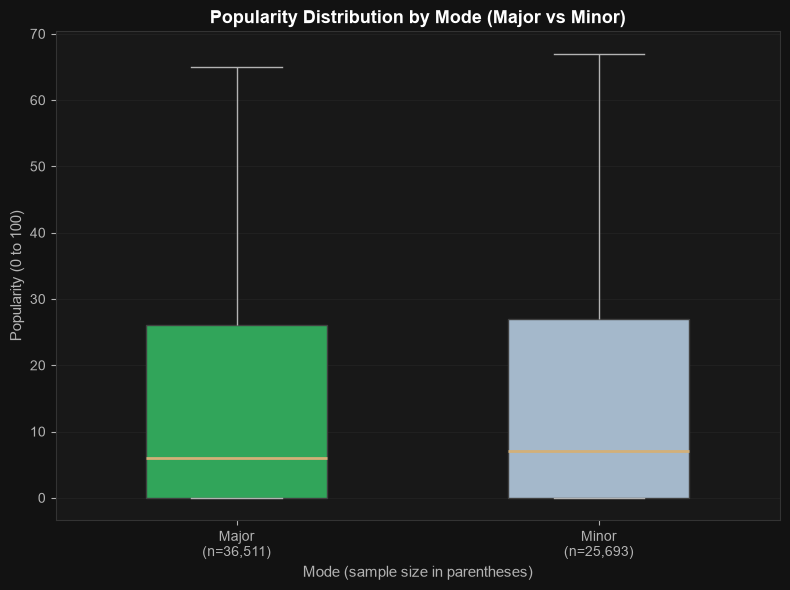

In [9]:
mode_names = {0: 'Minor', 1: 'Major'}
mode_order = ['Major', 'Minor']
mode_data = df_clean.dropna(subset=['mode']).copy()
mode_data['mode_label'] = mode_data['mode'].map(mode_names)
mode_counts = mode_data['mode_label'].value_counts()

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=mode_data,
    x='mode_label',
    y='popularity',
    order=mode_order,
    hue='mode_label',
    legend=False,
    palette={'Major': spotify_green, 'Minor': muted_blue},
    width=0.5,
    showfliers=False,
    medianprops=dict(color=muted_sand, linewidth=2),
    whiskerprops=dict(color=muted_grey),
    capprops=dict(color=muted_grey),
)
plt.xticks(
    range(len(mode_order)),
    [f'{name}\n(n={mode_counts[name]:,})' for name in mode_order],
)
plt.title('Popularity Distribution by Mode (Major vs Minor)')
plt.xlabel('Mode (sample size in parentheses)')
plt.ylabel('Popularity (0 to 100)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    bivariate_dir / 'popularity_by_mode.png', dpi=180,
    facecolor=plt.rcParams['figure.facecolor'],
)
plt.show(block=False)
plt.close()


#### Mode interpretation

1. **What the graph shows:** A grouped boxplot comparing major-mode tracks (n = 36,511) with minor-mode tracks (n = 25,693).
2. **Numerical evidence:** Major: mean **15.14**, median **6**. Minor: mean **15.68**, median **7**.
3. **Pattern:** The two distributions are very similar; minor is marginally higher, but the boxes overlap substantially.
4. **What it means:** Mode alone does not meaningfully separate popular from less popular tracks in this dataset.
5. **Limitations:** The groups are uneven in size, the comparison is descriptive with no control for other variables, and a small difference should not be interpreted as a causal effect of mode.

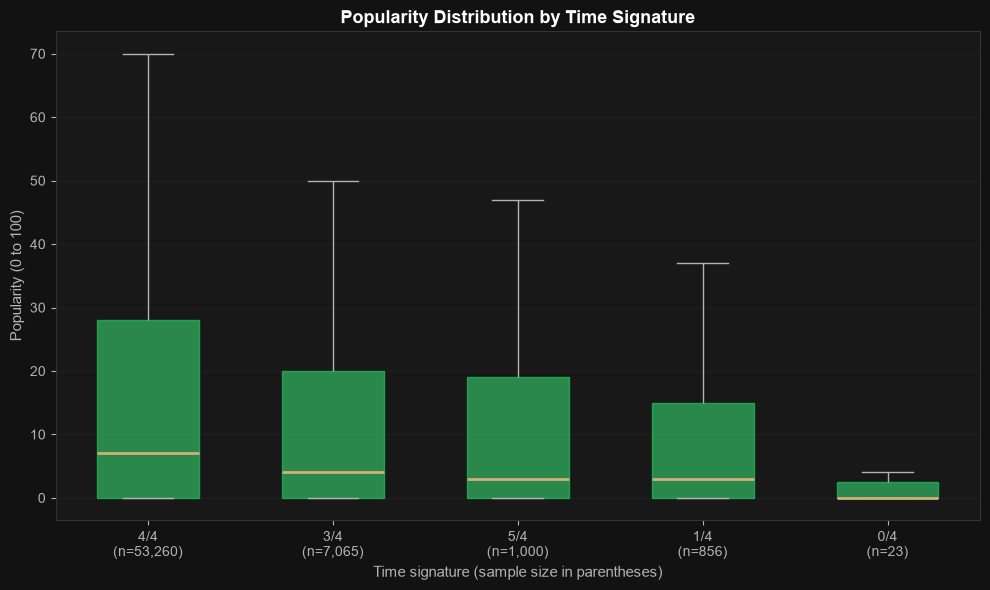

In [10]:
time_names = {4: '4/4', 3: '3/4', 5: '5/4', 1: '1/4', 0: '0/4'}
time_order_codes = [4, 3, 5, 1, 0]
time_data = df_clean.dropna(subset=['time_signature']).copy()
time_data['time_label'] = time_data['time_signature'].map(time_names)
time_order = [time_names[code] for code in time_order_codes
              if code in time_data['time_signature'].unique()]
time_counts = time_data['time_label'].value_counts()

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=time_data,
    x='time_label',
    y='popularity',
    order=time_order,
    color=spotify_green,
    width=0.55,
    showfliers=False,
    medianprops=dict(color=muted_sand, linewidth=2),
    boxprops=dict(alpha=0.8, edgecolor=spotify_green),
    whiskerprops=dict(color=muted_grey),
    capprops=dict(color=muted_grey),
)
plt.xticks(
    range(len(time_order)),
    [f'{name}\n(n={time_counts[name]:,})' for name in time_order],
)
plt.title('Popularity Distribution by Time Signature')
plt.xlabel('Time signature (sample size in parentheses)')
plt.ylabel('Popularity (0 to 100)')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(
    bivariate_dir / 'popularity_by_time_signature.png', dpi=180,
    facecolor=plt.rcParams['figure.facecolor'],
)
plt.show(block=False)
plt.close()


#### Time signature interpretation

1. **What the graph shows:** Popularity distributions for each time signature present after cleaning. The rare 0/4 category is kept because it exists in the data, but it has only 23 tracks.
2. **Numerical evidence:** 4/4: n = 53,260, mean **15.95**, median **7**. 3/4: n = 7,065, mean **12.20**, median **4**. 5/4: n = 1,000, mean **11.38**, median **3**. 1/4: n = 856, mean **9.62**, median **3**. 0/4: n = 23, mean **7.30**, median **0**.
3. **Pattern:** 4/4 is by far the most common signature and has the highest average popularity. The rarer signatures have lower averages and medians.
4. **What it means:** The pattern is descriptive. It may reflect the different catalogue composition of rare-signature tracks rather than a direct effect of time signature on popularity.
5. **Limitations:** The groups are unbalanced, the 0/4 group is tiny, no significance test or controls are applied, and boxplot outliers are hidden for readability.

In [11]:
def category_summary(values, popularity, group_name, label_map=None, order=None):
    data = pd.DataFrame({'category': values, 'popularity': popularity}).dropna()
    if label_map is not None:
        data['category'] = data['category'].map(label_map)
    summary = data.groupby('category')['popularity'].agg(
        track_count='count',
        mean_popularity='mean',
        median_popularity='median',
        std_popularity='std',
        min_popularity='min',
        max_popularity='max',
    ).reset_index()
    summary.insert(0, 'Group', group_name)
    if order is not None:
        order_map = {label: position for position, label in enumerate(order)}
        summary['sort_order'] = summary['category'].map(order_map)
        summary = summary.sort_values('sort_order').drop(columns='sort_order')
    return summary.rename(columns={
        'category': 'Category',
        'track_count': 'Track count',
        'mean_popularity': 'Mean popularity',
        'median_popularity': 'Median popularity',
        'std_popularity': 'Std popularity',
        'min_popularity': 'Min popularity',
        'max_popularity': 'Max popularity',
    })


mode_order_names = ['Major', 'Minor']
group_comparison = pd.concat([
    category_summary(df_clean['language'], df_clean['popularity'], 'Language', order=language_order),
    category_summary(df_clean['key'], df_clean['popularity'], 'Key',
                     label_map=key_names, order=[key_names[k] for k in key_order]),
    category_summary(df_clean['mode'], df_clean['popularity'], 'Mode',
                     label_map=mode_names, order=mode_order_names),
    category_summary(df_clean['time_signature'], df_clean['popularity'], 'Time signature',
                     label_map=time_names, order=time_order),
], ignore_index=True)

group_comparison.round(3).to_csv(
    table_dir / 'MEMBER2_GROUP_COMPARISON.csv', index=False
)
print('Group comparison table saved to outputs/tables/MEMBER2_GROUP_COMPARISON.csv')
print(group_comparison.round(2).to_string(index=False))


Group comparison table saved to outputs/tables/MEMBER2_GROUP_COMPARISON.csv
         Group  Category  Track count  Mean popularity  Median popularity  Std popularity  Min popularity  Max popularity
      Language   English        23389            14.76                5.0           18.93               0              93
      Language     Hindi         5740            18.20               11.0           19.40               0              83
      Language     Tamil        12609            11.91                3.0           16.10               0              80
      Language    Korean         6893            27.55               26.0           20.12               0              88
      Language    Telugu          321            14.32                9.0           14.76               0              66
      Language Malayalam          282             7.32                2.0           10.82               0              53
      Language   Unknown        13005            12.26                

The table above is the supporting evidence for the language, key, mode, and time-signature boxplots. `Track count` is the number of rows with a valid category and popularity value. Means and medians are descriptive summaries; no significance test is claimed.

## 9. E. Top 10 and bottom 10 tracks by popularity

Popularity ties are common, especially at zero. To make the lists **reproducible**, tracks are sorted by popularity first, then by release year (earlier first), then by track name, artist name, and finally `track_id`. This rule is used for both lists, so rerunning the notebook selects the same tracks.

The bottom list is a deterministic example: **17,698 tracks share a popularity score of 0**, so no unique "worst 10" exists. The charts show the selected 10, not all tied tracks. These lists describe the popularity column; they do not show that audio features caused success or failure.

Top 10 tracks by popularity:
 Rank                                           track_name                artist_name  year  popularity
    1                                            Big Dawgs         Hanumankind, Kalmi  2024          93
    2                                              Starboy      The Weeknd, Daft Punk  2016          91
    3                                      Blinding Lights                 The Weeknd  2020          91
    4 Bye Bye Bye - From Deadpool and Wolverine Soundtrack                     *NSYNC  2000          90
    5                                             cardigan               Taylor Swift  2020          89
    6                                            Anti-Hero               Taylor Swift  2022          89
    7                                 Locked out of Heaven                 Bruno Mars  2012          88
    8                                       Counting Stars                OneRepublic  2013          88
    9                             S

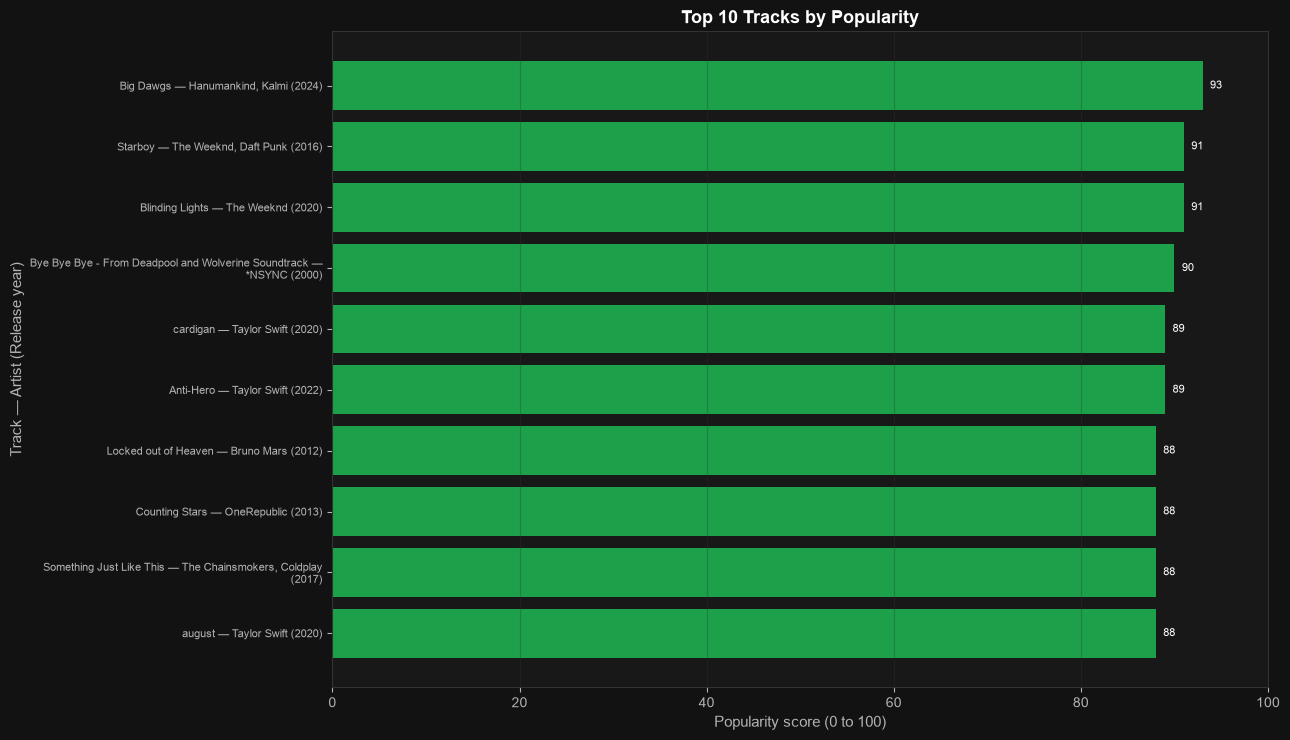

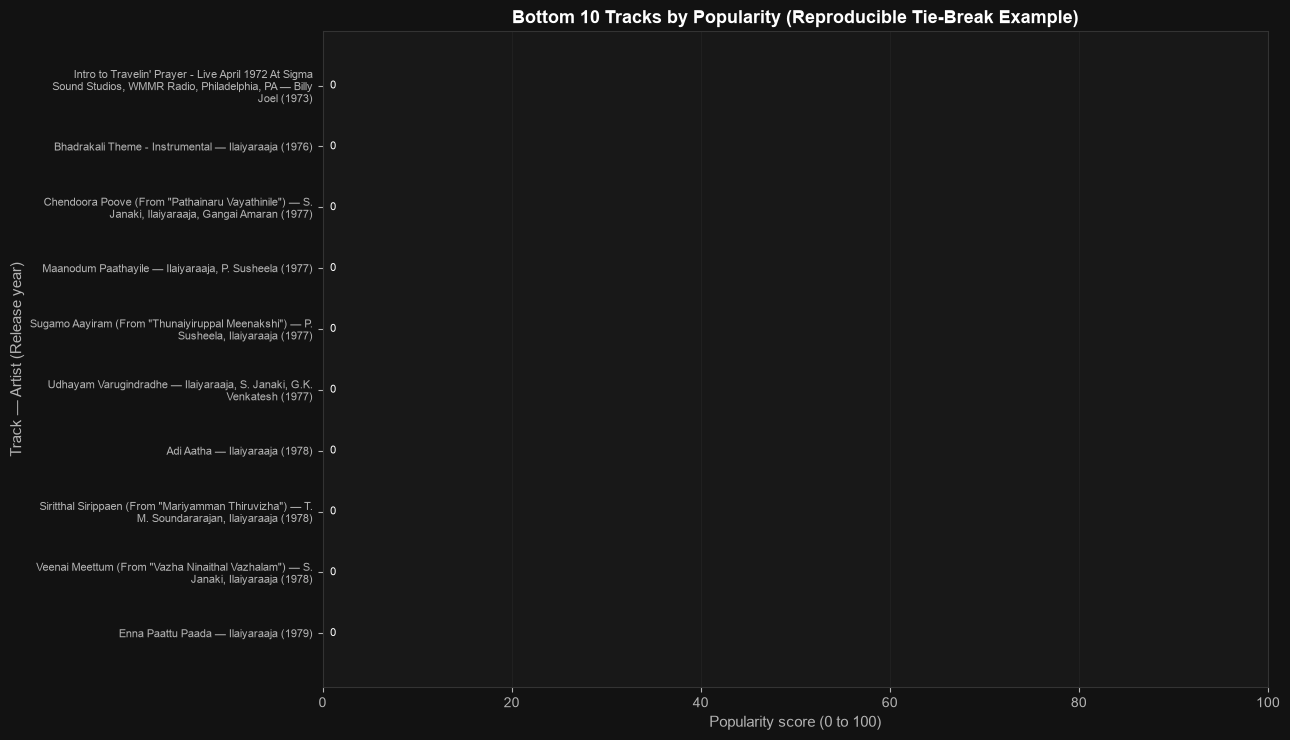

In [12]:
# Reproducible tie-breaking rule: popularity, then year, track, artist, track_id.
tie_break_columns = ['popularity', 'year', 'track_name', 'artist_name', 'track_id']
track_columns = ['track_name', 'artist_name', 'year', 'popularity']

top_10 = df_clean.sort_values(
    tie_break_columns, ascending=[False, True, True, True, True]
).head(10).copy()
bottom_10 = df_clean.sort_values(
    tie_break_columns, ascending=[True, True, True, True, True]
).head(10).copy()

top_10.insert(0, 'Rank', range(1, len(top_10) + 1))
bottom_10.insert(0, 'Rank', range(1, len(bottom_10) + 1))
top_10.insert(0, 'List', 'Top 10')
bottom_10.insert(0, 'List', 'Bottom 10')

top_bottom_tracks = pd.concat([top_10, bottom_10], ignore_index=True)[
    ['List', 'Rank', 'track_name', 'artist_name', 'year', 'popularity']
].rename(columns={
    'track_name': 'Track',
    'artist_name': 'Artist',
    'year': 'Release year',
    'popularity': 'Popularity',
})
top_bottom_tracks.to_csv(
    table_dir / 'MEMBER2_TOP_BOTTOM_TRACKS.csv', index=False
)

print('Top 10 tracks by popularity:')
print(top_10[['Rank'] + track_columns].to_string(index=False))
print()
print('Bottom 10 tracks by popularity (all tied at 0):')
print(bottom_10[['Rank'] + track_columns].to_string(index=False))


def draw_track_bar_chart(data, title, filename, bar_color):
    # The data is already ranked by popularity and the tie-break rule.
    # Reverse it so rank 1 appears at the top of the horizontal chart.
    plot_data = data.iloc[::-1].copy()
    plot_data['label'] = [
        textwrap.fill(f"{row.track_name} — {row.artist_name} ({row.year})", 55)
        for row in plot_data.itertuples()
    ]

    plt.figure(figsize=(13, 7.5))
    plt.barh(
        range(len(plot_data)), plot_data['popularity'],
        color=bar_color, alpha=0.85, edgecolor='none',
    )
    plt.yticks(range(len(plot_data)), plot_data['label'], fontsize=8)
    for position, value in enumerate(plot_data['popularity']):
        plt.text(value + 0.8, position, f'{value}', va='center', fontsize=8, color=text_white)
    plt.xlim(0, 100)
    plt.title(title)
    plt.xlabel('Popularity score (0 to 100)')
    plt.ylabel('Track — Artist (Release year)')
    plt.grid(True, axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        bivariate_dir / filename, dpi=180,
        facecolor=plt.rcParams['figure.facecolor'],
    )
    plt.show(block=False)
    plt.close()


draw_track_bar_chart(
    top_10,
    'Top 10 Tracks by Popularity',
    'top_10_tracks_by_popularity.png',
    spotify_green,
)
draw_track_bar_chart(
    bottom_10,
    'Bottom 10 Tracks by Popularity (Reproducible Tie-Break Example)',
    'bottom_10_tracks_by_popularity.png',
    muted_blue,
)


#### Top 10 and bottom 10 interpretation

1. **What the graphs show:** Horizontal bar charts of the selected top 10 and bottom 10 tracks. Each label includes the track name, artist, and release year, and each bar is annotated with its popularity score. Ties are resolved by popularity, then year (earlier first), track name, artist name, and track_id.
2. **Numerical evidence:** The top score is **93** for *Big Dawgs* (2024). The next scores are 91 (*Starboy*, 2016; *Blinding Lights*, 2020), 90 (*Bye Bye Bye*, 2000), 89 (*cardigan*, 2020; *Anti-Hero*, 2022), and four tracks at 88. All ten selected bottom tracks have popularity **0**, and **17,698 tracks (28.4%)** share that score.
3. **Pattern:** The top list contains different artists and years. The bottom list is a reproducible representative selection from a very large tie at zero, not a unique ranking.
4. **What it means:** These charts describe one platform popularity metric. A high score does not prove that audio features caused success, and a zero score does not prove low quality. Popularity can reflect streaming activity, playlist exposure, region, artist fame, catalogue matching, and the collection date.
5. **Limitations:** Ties are widespread, popularity is a snapshot rather than a lifetime measure, and these lists are not causal evidence about audio features.

## 10. Key findings from the bivariate analysis

1. **No audio feature is a strong stand-alone predictor of popularity.** Every popularity correlation in the heatmap is weak: the largest absolute values are loudness (Pearson **0.201**, Spearman **0.204**), energy (**0.147** / **0.131**), acousticness (**-0.138** / **-0.120**), and instrumentalness (**-0.127** / **-0.089**).
2. **Several features are essentially unrelated to popularity.** Valence (**0.009** / **-0.032**), liveness (**-0.012** / **-0.019**), tempo (**0.028** / **0.019**), and duration (**-0.040** / **-0.054**) are negligible. Danceability is **0.042** with Pearson but **-0.015** with Spearman, so its tiny association is not consistent.
3. **Audio features are more strongly related to each other than to popularity.** Energy vs loudness is **0.801** (Spearman **0.774**), energy vs acousticness **-0.643** (**-0.612**), danceability vs valence **0.632** (**0.595**), and energy vs danceability **0.466** (**0.360**). These overlaps mean bivariate popularity correlations should not be read in isolation.
4. **Language groups differ descriptively.** Korean has the highest median popularity (**26**, n = 6,893), while Malayalam (**2**, n = 282) and Tamil (**3**, n = 12,609) are lower. These differences may reflect catalogue composition, artists, release years, and audience coverage, not language itself.
5. **Key and mode show little separation.** Key means range only from **13.92** (F) to **16.40** (D#/Eb); major and minor medians are **6** and **7**. 4/4 time is both the most common signature (n = 53,260) and has the highest mean (**15.95**); rarer signatures are lower but are much smaller groups.
6. **Top and bottom lists are descriptive, not causal.** The top score is **93**; the bottom list is one reproducible selection from **17,698** tracks tied at 0. Popularity does not reveal why a track succeeded, and these results do not prove causation.
7. **Overall:** bivariate analysis gives useful screening evidence but cannot isolate effects. Multivariable analysis and careful controls would be needed before making causal or prescriptive claims.